# Deflectometry

Look at a car body, a spectacle lens or a smartphone display at a
grazing angle and you see the reflections of window frames bend wherever
the surface is not quite right. **Phase measuring deflectometry** (PMD)
makes this quantitative: a camera looks at a specular surface and sees,
reflected in it, a monitor that shows phase-shifted sinusoidal fringes.
For every camera pixel the phases tell which screen point it sees; the
law of reflection turns the line of sight and the ray to that screen
point into a surface normal, and the slopes are integrated to the shape.

Deflectometry needs nothing but a monitor, a camera and a computer, it
measures freeforms and strongly curved surfaces without null optics,
and it reaches nanometres on the mid-spatial frequency ripples of a few
millimetres that matter for imaging quality. It measures slopes, though,
not heights, and that has consequences: the height-slope ambiguity, and
low-order shape errors from the calibration of the geometry.

This notebook uses the `deflectometry` module together with the fringe
tools of fringe projection (notebook 133, triangulation and structured
light) and phase shifting (notebook 23, interferometry):

1. the geometry and the fringe image of a concave mirror,
2. decoding the screen coordinates: phase shifting, temporal unwrapping,
   defocus of the screen, noise and slope resolution,
3. the reconstruction of the surface by iterating slopes and heights,
4. the height-slope ambiguity,
5. calibration errors: why deflectometry is strong on ripples and weak
   on power.

Lengths in mm, camera focal lengths in pixels.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import deflectometry as df
from pyoptics import sketch
from pyoptics.structured_light import Pinhole, look_at, fringe_patterns, temporal_unwrap
from pyoptics.interferometry import psi_n_step

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

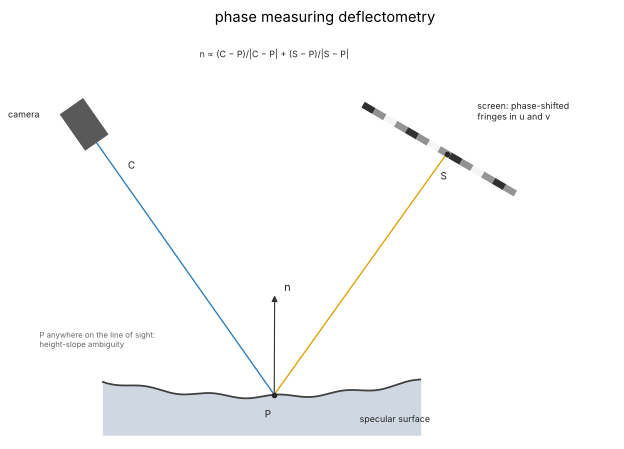

In [2]:
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
sketch.metrology_layout(ax, "deflectometry", title="phase measuring deflectometry")
plt.show()

## 1. Geometry and the fringe image

The surface under test is a concave mirror of 100 mm diameter with a
radius of 3 m, a little astigmatism and a mid-spatial frequency ripple
of the kind diamond turning or sub-aperture polishing leaves: 40 nm
amplitude at a period of 6 mm. A camera of 320 × 320 pixels and a
monitor of 1920 × 1080 pixels of 0.25 mm hang 600 mm above it, 240 mm
apart. `df.trace()` finds for every camera pixel the point on the mirror
and the screen point it sees.

pixels on the mirror: 66758, pixel footprint 0.34 mm, screen area used: u 656..1273, v 221..858 px


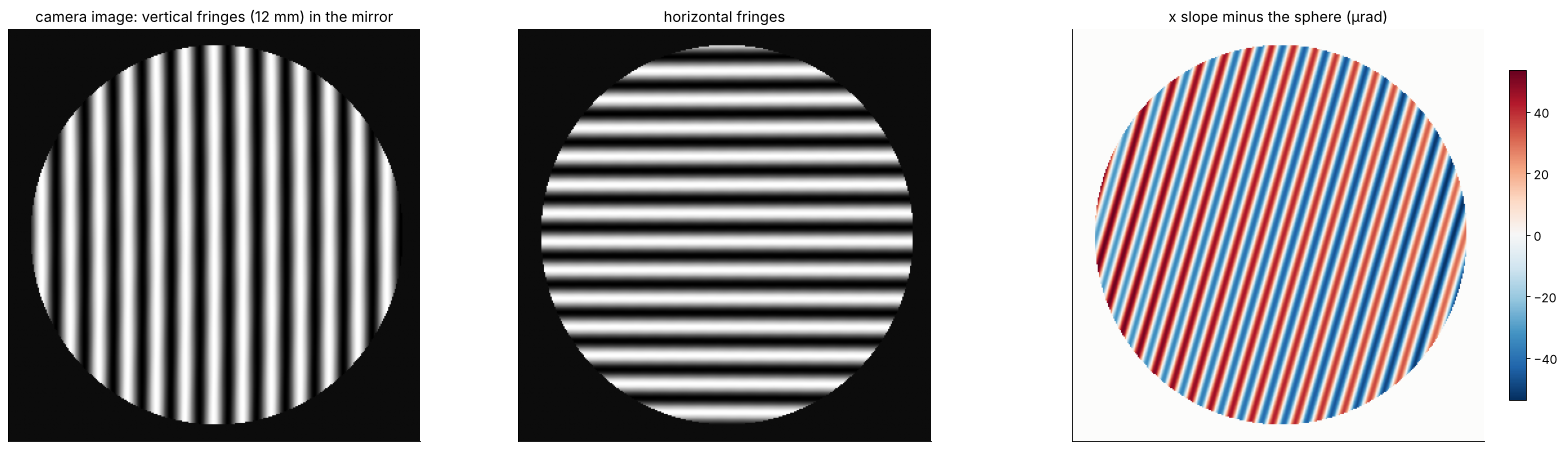

In [3]:
R_MIRROR, RADIUS = 3000.0, 50.0
A_AST, A_RIP, P_RIP = 3e-4, 4e-5, 6.0          # 300 nm astigmatism, 40 nm ripple, 6 mm period


def surface(X, Y):
    return ((X**2 + Y**2)/(2*R_MIRROR) + A_AST*(X**2 - Y**2)/RADIUS**2
            + A_RIP*np.cos(2*np.pi*(X + 0.3*Y)/P_RIP))


def slopes(X, Y):
    s = -A_RIP*2*np.pi/P_RIP*np.sin(2*np.pi*(X + 0.3*Y)/P_RIP)
    return X/R_MIRROR + 2*A_AST*X/RADIUS**2 + s, Y/R_MIRROR - 2*A_AST*Y/RADIUS**2 + 0.3*s


cam_pos, scr_pos = np.array([-120.0, 0, 600]), np.array([120.0, 0, 600])
camera = Pinhole(cam_pos, look_at(cam_pos, (0, 0, 0)), 1800.0, (320, 320))
screen = df.Screen(scr_pos, look_at(scr_pos, (0, 0, 0)), 0.25, (1920, 1080))
P, u_s, v_s = df.trace(camera, screen, surface, slopes)
on_mirror = np.hypot(P[..., 0], P[..., 1]) < RADIUS
u_s[~on_mirror], v_s[~on_mirror] = np.nan, np.nan
D_SCREEN = np.linalg.norm(scr_pos)                 # surface to screen, about 612 mm
print("pixels on the mirror: {}, pixel footprint {:.2f} mm, screen area used: u {:.0f}..{:.0f}, "
      "v {:.0f}..{:.0f} px".format(on_mirror.sum(), 100/np.sqrt(on_mirror.sum()/np.pi*4),
                                  np.nanmin(u_s), np.nanmax(u_s), np.nanmin(v_s), np.nanmax(v_s)))
fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), layout="constrained")
img = np.where(on_mirror, 0.5 + 0.5*np.cos(2*np.pi*u_s/48), 0.05)
axs[0].imshow(img, cmap="gray", origin="lower")
axs[0].set_title("camera image: vertical fringes (12 mm) in the mirror")
img2 = np.where(on_mirror, 0.5 + 0.5*np.cos(2*np.pi*v_s/48), 0.05)
axs[1].imshow(img2, cmap="gray", origin="lower")
axs[1].set_title("horizontal fringes")
gx, gy = slopes(P[..., 0], P[..., 1])
im = axs[2].imshow(np.where(on_mirror, (gx - P[..., 0]/R_MIRROR)*1e6, np.nan), cmap="RdBu_r",
                   origin="lower")
axs[2].set_title("x slope minus the sphere (µrad)")
plt.colorbar(im, ax=axs[2], shrink=0.8)
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

The fringes look almost straight: the mirror is nearly spherical, and
40 nm of ripple are 40 µrad of slope, which bends a fringe of 48 pixels
by a fraction of a pixel on the screen. The slope map (right) is what
the measurement must find: the ripple (±40 µrad) and the astigmatism
(±10 µrad at the edge).

## 2. Decoding the screen coordinates

The monitor shows $N$ phase-shifted sinusoids along $u$ and along $v$,
for a sequence of periods: the coarsest covers the whole screen and is
unambiguous, the finest sets the precision, and temporal unwrapping
combines them (`structured_light.temporal_unwrap()`, as in fringe
projection). Two things are specific to deflectometry:

- The camera is focused on the mirror, not on the screen, so the screen
  is blurred. For a flat mirror the virtual screen is at twice the
  distance, and a camera with the entrance pupil $D$ blurs each screen
  point into a disc of about $D\,d_\mathrm{screen}/d_\mathrm{mirror}$
  on the screen (`df.blur_diameter()`). Sinusoids stay sinusoids under
  any blur, only their contrast drops (`df.defocus_contrast()`); this
  is why deflectometry uses sinusoidal fringes and not binary codes.
- A screen point found with the uncertainty $\delta s$ at the distance
  $d$ from the surface gives the slope uncertainty $\delta s/(2d)$
  (`df.slope_resolution()`), and the phase noise $\delta\phi$ of
  fringes of the period $p$ is $\delta s = p\,\delta\phi/2\pi$.

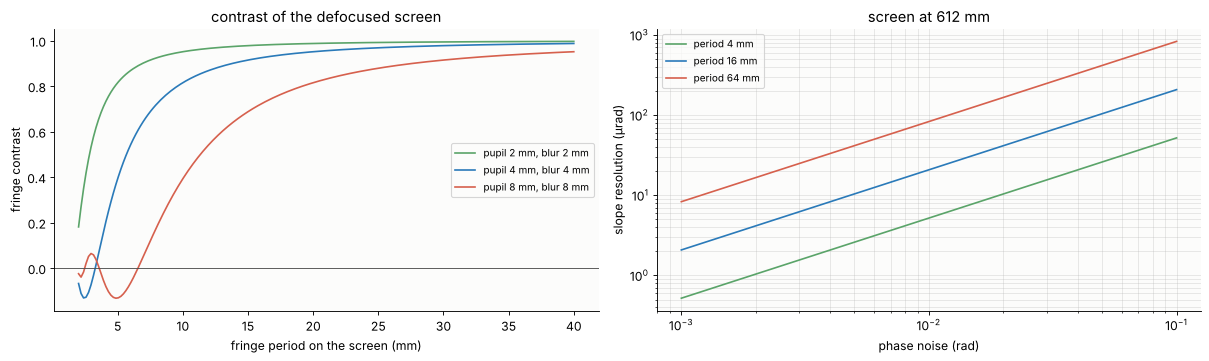

In [4]:
periods_mm = np.linspace(2, 40, 200)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
for D, c in ((2.0, GREEN), (4.0, BLUE), (8.0, RED)):
    b = df.blur_diameter(D, 610.0, 610.0)
    axs[0].plot(periods_mm, df.defocus_contrast(periods_mm, b), color=c,
                label="pupil {:.0f} mm, blur {:.0f} mm".format(D, b))
axs[0].axhline(0, color="0.3", lw=0.8)
axs[0].set_xlabel("fringe period on the screen (mm)")
axs[0].set_ylabel("fringe contrast")
axs[0].set_title("contrast of the defocused screen")
axs[0].legend(fontsize=9)
noise = np.logspace(-3, -1, 50)                      # phase noise (rad)
for p, c in ((4.0, GREEN), (16.0, BLUE), (64.0, RED)):
    axs[1].loglog(noise, df.slope_resolution(df.screen_uncertainty(p, noise), D_SCREEN)*1e6,
                  color=c, label="period {:.0f} mm".format(p))
axs[1].set_xlabel("phase noise (rad)")
axs[1].set_ylabel("slope resolution (µrad)")
axs[1].set_title("screen at {:.0f} mm".format(D_SCREEN))
axs[1].grid(alpha=0.3, which="both")
axs[1].legend(fontsize=9)
plt.show()

A camera with a 4 mm entrance pupil blurs the screen by about 4 mm, so
fringes of 16 mm keep 90 % contrast while those of 4 mm are nearly gone:
the finest usable period is set by the defocus, not by the monitor's
pixels. With 16 mm fringes, a phase noise of 0.01 rad gives a slope
resolution of about 20 µrad.

Now the full measurement: 8 phase steps for each of the periods 1920,
256 and 64 screen pixels (480, 64 and 16 mm), in $u$ and $v$, 48 camera
images with 1 % intensity noise, a projector gamma of 1 (monitors are
linearized for deflectometry), and the fringe contrast reduced by the
blur of a 4 mm pupil.

In [5]:
rng = np.random.default_rng(7)
N_STEPS = 8
PERIODS = (1920.0, 256.0, 64.0)
BLUR = df.blur_diameter(4.0, 610.0, D_SCREEN)
SIGMA_I = 0.01


def capture(coord, period):
    """Camera images of phase shifted fringes along one screen axis."""
    contrast = df.defocus_contrast(period*screen.pitch, BLUR)
    I = fringe_patterns(np.nan_to_num(coord), period, N_STEPS, offset=0.5, amplitude=0.45*contrast)
    return I + SIGMA_I*rng.standard_normal(I.shape)


def decode(coord):
    phases = [psi_n_step(capture(coord, p))[0] for p in PERIODS]
    return np.where(on_mirror, temporal_unwrap(phases, PERIODS), np.nan)


t0 = time.time()
u_m, v_m = decode(u_s), decode(v_s)
print("decoding: {:.1f} s".format(time.time() - t0))
err_u = (u_m - u_s)*screen.pitch
err_v = (v_m - v_s)*screen.pitch
gross = np.nanmean(np.abs(err_u) > 1.0)
print("screen coordinate error: {:.4f} mm rms in u, {:.4f} mm in v; unwrapping failures {:.2%}".format(
    np.nanstd(err_u), np.nanstd(err_v), gross))
print("expected slope noise: {:.1f} urad".format(df.slope_resolution(np.nanstd(err_u), D_SCREEN)*1e6))

decoding: 0.2 s
screen coordinate error: 0.0305 mm rms in u, 0.0306 mm in v; unwrapping failures 0.00%
expected slope noise: 24.9 urad


The decoded screen coordinates scatter by about 25 µm, a sixth of a
monitor pixel, without unwrapping failures, which corresponds to a slope
noise of about 20 µrad: half the slope of the ripple. (The sign of the
phase in `psi_n_step()` matches `fringe_patterns()`, so the unwrapped
phase is the screen coordinate directly.)

## 3. Reconstruction

The slopes follow from the law of reflection once the surface point is
known: the normal bisects the directions to the camera and to the screen
point (`df.slopes_from_points()`). But the surface point is what we want
to measure. `df.reconstruct()` iterates: start from a flat surface at a
known height, intersect the lines of sight with it, compute the slopes,
resample them onto a regular grid, integrate them by least squares
(Frankot-Chellappa, `freeform.integrate_gradient()`), shift the result
through a known point (here the vertex, as a distance sensor would give
it) and repeat with the new surface.

reconstruction: 10 s
rms height error after each iteration (nm): 1047.5, 11.1, 12.1, 12.1, 12.1


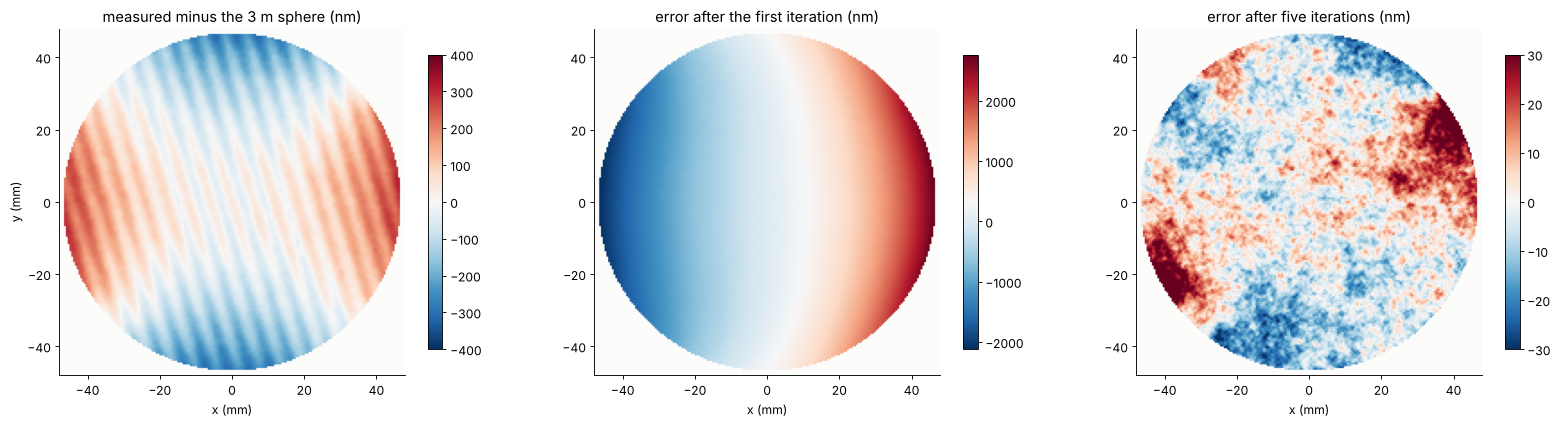

In [6]:
Z_VERTEX = surface(0.0, 0.0)                       # the known point, e.g. from a distance sensor
x = np.linspace(-48, 48, 193)
y = np.linspace(-48, 48, 193)
X, Y = np.meshgrid(x, y, indexing="ij")
inside = np.hypot(X, Y) < 47.0
t0 = time.time()
Z, gx_r, gy_r, history = df.reconstruct(camera, screen, u_m, v_m, x, y, anchor=(0.0, 0.0, Z_VERTEX),
                                        n_iter=5)
print("reconstruction: {:.0f} s".format(time.time() - t0))
truth = surface(X, Y)
rms = [np.nanstd(np.where(inside, H - truth, np.nan))*1e6 for H in history]
print("rms height error after each iteration (nm):", ", ".join("{:.1f}".format(r) for r in rms))
fig, axs = plt.subplots(1, 3, figsize=(20, 5.2), layout="constrained")
sphere = (X**2 + Y**2)/(2*R_MIRROR)
for ax, data, t, lim in ((axs[0], (Z - sphere)*1e6, "measured minus the 3 m sphere (nm)", 400),
                         (axs[1], (history[0] - truth)*1e6, "error after the first iteration (nm)", None),
                         (axs[2], (Z - truth)*1e6, "error after five iterations (nm)", 30)):
    im = ax.imshow(np.where(inside, data, np.nan).T, origin="lower", extent=(-48, 48, -48, 48),
                   cmap="RdBu_r", vmin=-lim if lim else None, vmax=lim if lim else None)
    ax.set_title(t)
    ax.set_xlabel("x (mm)")
    plt.colorbar(im, ax=ax, shrink=0.85)
axs[0].set_ylabel("y (mm)")
plt.show()

The first iteration, with the surface points on the flat start plane,
is off by micrometres, mostly in tilt and power: the sagitta of the 3 m
sphere is 0.4 mm at the edge, and the oblique lines of sight meet the
true surface at slightly different points with different normals. The second iteration
already reaches the noise of the measurement, 12 nm rms, with the 40 nm
ripple and the astigmatism fully resolved; more iterations change
nothing. The remaining error has the look of integrated slope noise:
white noise in the slopes becomes smooth blotches in the height, whose
amplitude grows towards low spatial frequencies.

A cut along x shows the ripple:

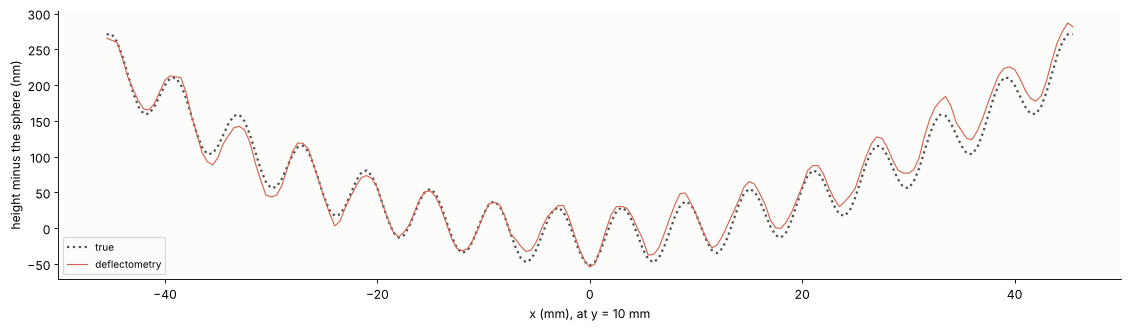

In [7]:
j = np.argmin(np.abs(y - 10.0))
fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
sel = inside[:, j]
ax.plot(x[sel], (truth[sel, j] - sphere[sel, j])*1e6, color="0.3", lw=2, ls=":", label="true")
ax.plot(x[sel], (Z[sel, j] - sphere[sel, j])*1e6, color=RED, lw=1, label="deflectometry")
ax.set_xlabel("x (mm), at y = 10 mm")
ax.set_ylabel("height minus the sphere (nm)")
ax.legend(fontsize=9)
plt.show()

## 4. The height-slope ambiguity

Without the known point, or with a wrong one, the iteration converges to
a different surface: a mirror closer to the camera, with normals tilted
so that it shows the same screen points. One measurement determines a
one-parameter family of surfaces; the known height picks one. How
sensitive is the result to the anchor?

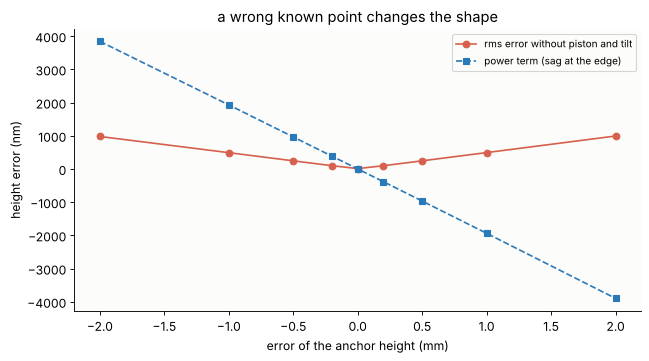

anchor error -2.0 mm: shape error  979.6 nm rms, power +3843.8 nm
anchor error -1.0 mm: shape error  492.0 nm rms, power +1930.3 nm
anchor error -0.5 mm: shape error  246.1 nm rms, power  +965.0 nm
anchor error -0.2 mm: shape error   99.2 nm rms, power  +386.9 nm
anchor error +0.0 mm: shape error   11.9 nm rms, power    +1.9 nm
anchor error +0.2 mm: shape error   98.8 nm rms, power  -384.1 nm
anchor error +0.5 mm: shape error  246.4 nm rms, power  -965.2 nm
anchor error +1.0 mm: shape error  494.3 nm rms, power -1937.9 nm
anchor error +2.0 mm: shape error  993.4 nm rms, power -3896.4 nm


In [8]:
offsets = np.array([-2.0, -1.0, -0.5, -0.2, 0.0, 0.2, 0.5, 1.0, 2.0])
rms_off, power_off = [], []
r2 = (X**2 + Y**2)/RADIUS**2
for dz in offsets:
    Zo, _, _, _ = df.reconstruct(camera, screen, u_m, v_m, x, y, anchor=(0.0, 0.0, Z_VERTEX + dz), n_iter=4)
    e = np.where(inside, Zo - truth, np.nan)
    ok = inside & np.isfinite(e)
    # remove piston and tilt (alignment), then fit the power term r^2/R^2
    A = np.stack([np.ones(ok.sum()), X[ok]/RADIUS, Y[ok]/RADIUS, r2[ok]], axis=-1)
    c = np.linalg.lstsq(A, e[ok], rcond=None)[0]
    rest = e[ok] - A[:, :3] @ c[:3]
    rms_off.append(np.std(rest)*1e6)
    power_off.append(c[3]*1e6)
fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
ax.plot(offsets, rms_off, "o-", color=RED, label="rms error without piston and tilt")
ax.plot(offsets, power_off, "s--", color=BLUE, label="power term (sag at the edge)")
ax.set_xlabel("error of the anchor height (mm)")
ax.set_ylabel("height error (nm)")
ax.set_title("a wrong known point changes the shape")
ax.legend(fontsize=9)
plt.show()
for dz, r, p in zip(offsets, rms_off, power_off):
    print("anchor error {:+.1f} mm: shape error {:6.1f} nm rms, power {:+7.1f} nm".format(dz, r, p))

An error of the known height does not just shift the surface: it tilts
it (the camera and the screen look from the side) and changes its
curvature, by about 2 µm of sag at the edge per millimetre of anchor
error, nearly all of the error once piston and tilt are removed. The
ripple and the astigmatism are hardly affected. To keep the power
error at 10 nm the height of the known point must be right to about
5 µm; a touch probe or a confocal distance sensor does that. Stereo
deflectometry (two cameras, or one camera and two screen positions)
resolves the ambiguity without a known point, because only the true
surface explains both views.

## 5. Calibration and the spatial frequencies

The reconstruction uses the positions of camera and screen and the
camera's focal length; they come from a calibration, and their errors
act like the anchor error: they change the normals smoothly over the
aperture and therefore the low orders of the shape. Ripples are measured
with the local slope difference, which a geometry error hardly changes.
Below the screen is placed 0.5 mm farther away than the reconstruction
assumes, and the error of the result is split into a low-order part
(polynomials up to fourth degree) and the rest.

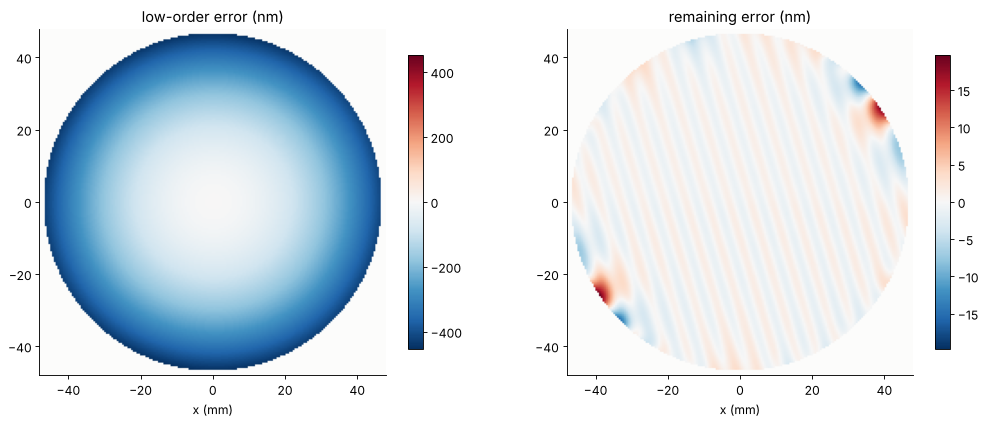

screen 0.5 mm too far: low-order error 126 nm rms (PV 455 nm), remaining 1.70 nm rms


In [9]:
scr_true = df.Screen(scr_pos*(1 + 0.5/D_SCREEN), look_at(scr_pos, (0, 0, 0)), 0.25, (1920, 1080))
_, u_c, v_c = df.trace(camera, scr_true, surface, slopes)
u_c[~on_mirror], v_c[~on_mirror] = np.nan, np.nan
Zc, _, _, _ = df.reconstruct(camera, screen, u_c, v_c, x, y, anchor=(0.0, 0.0, Z_VERTEX), n_iter=4)
err = np.where(inside, Zc - truth, np.nan)
ok = np.isfinite(err)
xn, yn = X/RADIUS, Y/RADIUS
basis = np.stack([xn**i*yn**j for i in range(5) for j in range(5 - i)], axis=-1)
coef = np.linalg.lstsq(basis[ok], err[ok], rcond=None)[0]
low = np.where(ok, basis @ coef, np.nan)
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), layout="constrained")
for ax, data, t in ((axs[0], low, "low-order error (nm)"), (axs[1], err - low, "remaining error (nm)")):
    lim = np.nanmax(np.abs(data))*1e6
    im = ax.imshow(data.T*1e6, origin="lower", extent=(-48, 48, -48, 48), cmap="RdBu_r",
                   vmin=-lim, vmax=lim)
    ax.set_title(t)
    ax.set_xlabel("x (mm)")
    plt.colorbar(im, ax=ax, shrink=0.85)
plt.show()
print("screen 0.5 mm too far: low-order error {:.0f} nm rms (PV {:.0f} nm), remaining {:.2f} nm rms"
      .format(np.nanstd(low)*1e6, (np.nanmax(low) - np.nanmin(low))*1e6, np.nanstd(err - low)*1e6))

Half a millimetre of screen distance, a typical calibration error,
costs over a hundred nanometres of low-order shape, while the rest,
ripple and astigmatism included, is measured to under 2 nm (no noise in
this run). This is the division of labour in optics shops:
deflectometry for mid-spatial
frequencies and freeform shape on parts that interferometers cannot
null, interferometry or a calibrated reference for power and other low
orders. The same split holds for the noise: integrating slopes turns a
white slope noise into a height noise that grows towards low spatial
frequencies, the opposite of an interferometer's height noise.

## Summary

- Deflectometry measures surface slopes from the screen points seen in
  a specular surface; phase shifting and temporal unwrapping decode them
  to a fraction of a monitor pixel, and sinusoidal fringes survive the
  defocus of the screen.
- The slope resolution is $\delta s/(2d)$, tens of microradians with
  simple hardware, which integrates to nanometres on millimetre ripples.
- Heights come from iterating slopes, integration and a known point;
  an error of the known point or of the calibrated geometry changes the
  low orders (power) of the shape, but hardly the ripple.
- Deflectometry therefore complements interferometry: strong on
  mid-spatial frequencies and freeforms, weak on absolute power.

## References

- M. C. Knauer, J. Kaminski and G. Häusler, "Phase measuring
  deflectometry: a new approach to measure specular free-form
  surfaces", Proc. SPIE 5457, 366 (2004).
- P. Su, R. E. Parks, L. Wang, R. P. Angel and J. H. Burge, "Software
  configurable optical test system: a computerized reverse Hartmann
  test", Appl. Opt. 49, 4404 (2010).
- L. Huang, M. Idir, C. Zuo and A. Asundi, "Review of phase measuring
  deflectometry", Opt. Lasers Eng. 107, 247 (2018).
- G. Häusler, C. Faber, E. Olesch and S. Ettl, "Deflectometry vs.
  interferometry", Proc. SPIE 8788, 87881C (2013).
- R. T. Frankot and R. Chellappa, "A method for enforcing integrability
  in shape from shading algorithms", IEEE Trans. Pattern Anal. Mach.
  Intell. 10, 439 (1988).

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 98 s
